# <span style="color:darkblue"> Lecture 14a: Regression Trees
 </span>

<font size = "5">



<font size = "5">

Install the "graphviz" library. In the terminal:

```pip install graphviz``` (Visualize regression trees) <br>
```pip install ISLP```     (Data from Intro to Statistical Learning)

If the Graphviz is not working

``` conda install python-graphviz ```

# <span style="color:darkblue"> I. Setup Working Environment </span>


In [11]:
%pip install graphviz

# The "pandas" library is used for processing datasets
# The "numpy" is for numeric observations and random numbers
# The "matplotlib.pyplot" library is for creating graphs

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# We will use the "sklearn" package

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor as DTR
from sklearn import tree
import sklearn.model_selection as skm
from sklearn.ensemble import RandomForestRegressor as RF


# This is used to create data matrices
import patsy

# This is used to visualize regreesion trees
import graphviz

# Import content from the book "Introduction to Statistical Learning"
# Install the package if it is not already available in the notebook environment
%pip install ISLP

# Import content from the book "Introduction to Statistical Learning"
import ISLP


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# <span style="color:darkblue"> II. Mashable Dataset </span>


<font size = "5">

Mashable is a news website, digital media platform <br> 
and entertainment company. Our goal will be to predict which articles <br>
get shared most often. We will be working with a subset of the data <br>
compiled by the following authors:

Original Article <br>
https://repositorium.sdum.uminho.pt/bitstream/1822/39169/1/main.pdf

The Kaggle data repository <br>
https://www.kaggle.com/datasets/thehapyone/uci-online-news-popularity-data-set


In [12]:
articles_train  = pd.read_csv("data_raw/ArticlesTrain.csv")
articles_test   = pd.read_csv("data_raw/ArticlesTest.csv")


<font size = "5">

Create features matrix ($X$) and labels/outcomes $(Y)$


In [13]:
# Extract all columns except "shares" (the outcome)
X_train = articles_train.drop(columns = ["shares"])
X_test  = articles_test.drop(columns = ["shares"])

# Extract shares (the outcome)
y_train = articles_train[["shares"]]
y_test = articles_test[["shares"]]

<font size = "5">

Train regression tree

- Compute $\widehat{f}(x)$
- Random state sets a seed for tie breaking

In [14]:
tree_model = DTR(max_depth=3,random_state = 0) 
X_train = articles_train.drop(columns=["shares"])
y_train = articles_train["shares"]

tree_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_

<font size = "5">

Evaluate out-of-sample mean squared error (MSE)

- $\mathcal{I}_{train}\quad$  (training data)
- $\mathcal{I}_{test}\quad$ (test data)

$ MSE = \frac{1}{n_{test}}\sum_{i \in \mathcal{I}_{test}} (y_i - \widehat{f}(X_i))^2 $

In [15]:
# Convert y_test to array for comparison
X_test = articles_test.drop(columns=["shares"])
y_test_array = articles_test["shares"].to_numpy()

# Compute MSE
np.mean((y_test_array- tree_model.predict(X_test))**2)

np.float64(0.6422959060296387)

<font size = "5">

Display Tree

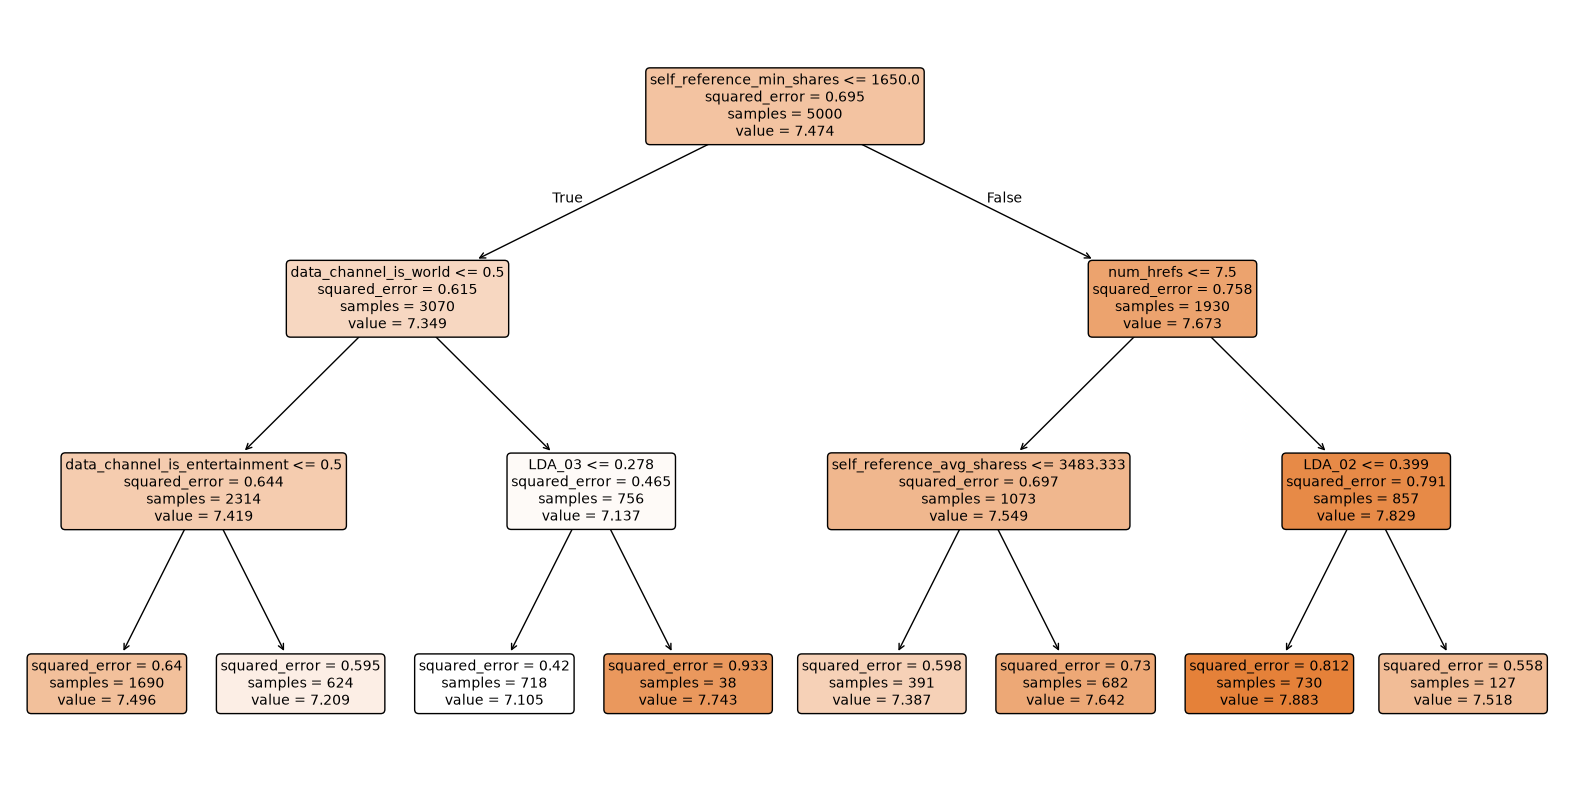

In [24]:
# Can add custom names in "feature_names"
# "filled = True" shows colors
import matplotlib.pyplot as plt
from sklearn import tree

plt.figure(figsize=(20, 10))

tree.plot_tree(
    tree_model,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()

<font size = "5">

Cost Complexity Pruning (CCP)

- Depends on a tuning parameter (ccp)
- We split training data into folds to compute the <br>
optimal CCP parameter


In [17]:
ccp_path = tree_model.cost_complexity_pruning_path(X_train, y_train) 

kfold = skm.KFold(5,
                  shuffle=True,
                  random_state=10) 

grid = skm.GridSearchCV(tree_model,
                        {'ccp_alpha': ccp_path.ccp_alphas},
                        refit=True,
                        cv=kfold, 
                        scoring='neg_mean_squared_error')

G = grid.fit(X_train, y_train)

In [18]:
pruned_tree = grid.best_estimator_
np.mean((np.array(y_test) - pruned_tree.predict(X_test))**2)

np.float64(0.7286472382489199)

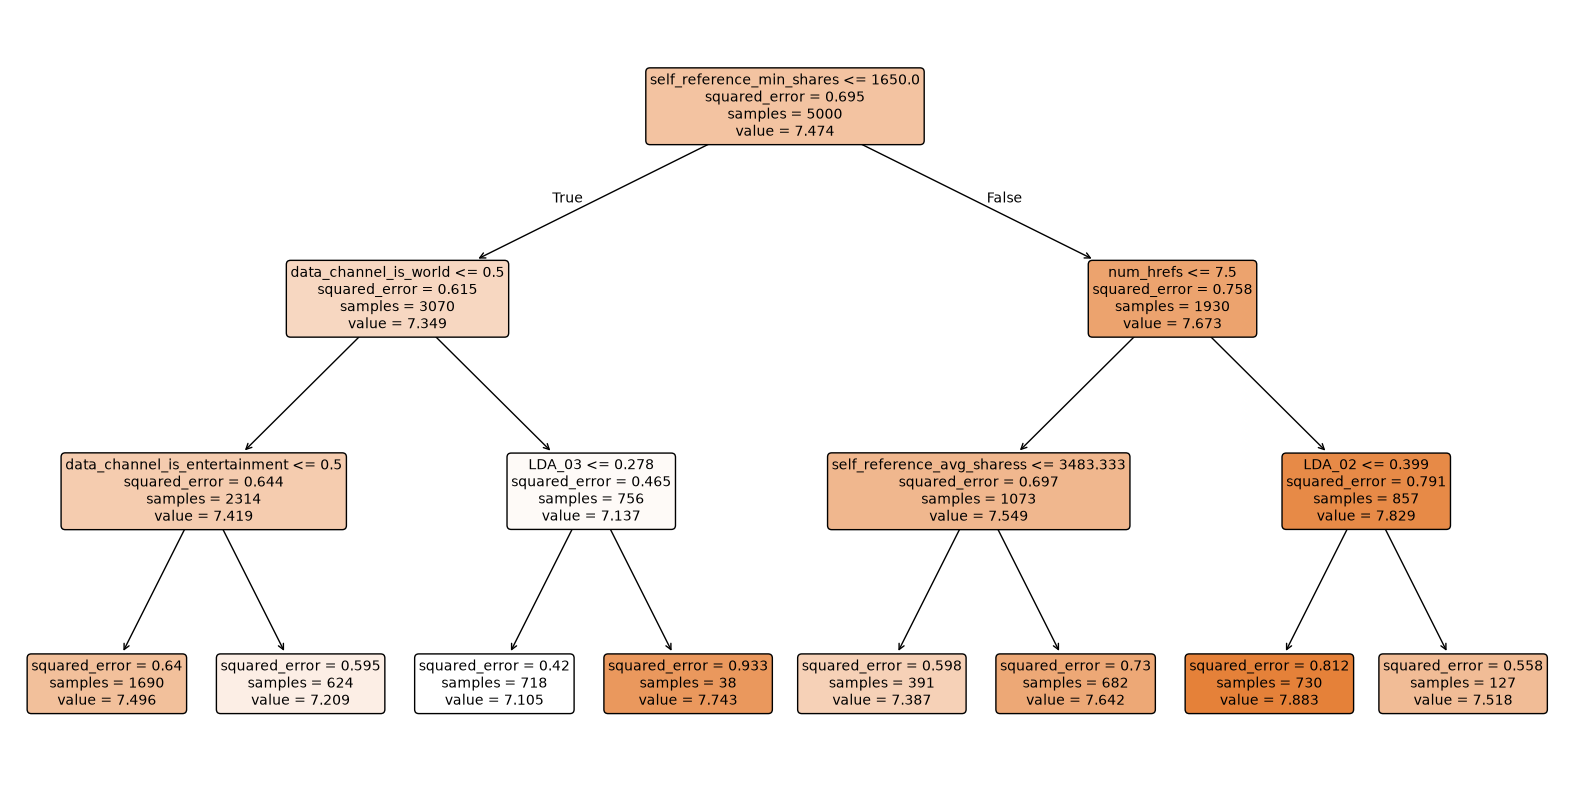

In [25]:
import matplotlib.pyplot as plt
from sklearn import tree

plt.figure(figsize=(20, 10))

tree.plot_tree(
    pruned_tree,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()

# <span style="color:darkblue"> IV. Exercises </span>


<font size = "5">

Try it yourself!

For this exercises we will be working with a <br>
A data set containing housing values in 506 suburbs of Boston

In [20]:
Boston =  ISLP.load_data("Boston")

<font size = "5">

(a) Run a regression tree to predict the "crim" (crime) variable <br>
using all other neighborhood information, prune the tree, <br>
and report out-of-sample MSE

- Use two different tree depths. How does this affect <br>
out-of-sample performance?

In [21]:
# Write your own code






<font size = "5">

(b) Run a linear regression using the same data. <br>
Which method has the lowest out-of-sample MSE? 

In [22]:
# Write your own code





